3.1  LOADING RESEARCH ARTICLES INTO A DATAFRAME


,article_id,filename,word_count,char_count
0,research_1,research_1.txt,5602,38160
1,research_2,research_2.txt,2416,16104
2,research_3,research_3.txt,3828,26154
3,research_4,research_4.txt,5922,38950
4,research_5,research_5.txt,4027,26831



3.2  DENOISING / PREPROCESSING ARTICLES


,article_id,word_count,clean_word_count
0,research_1,5602,2888
1,research_2,2416,1191
2,research_3,3828,1926
3,research_4,5922,3003
4,research_5,4027,2033



Sample cleaned text (first article, first 300 chars):
purpose position mixed method mixed synonym natural complement traditional qualitative quantitative present pragmatism offering attractive philosophical partner mixed method provide framework designing conducting mixed method briefly review paradigm war incompatibility thesis show commonality quanti ...

3.3  EXTRACTIVE SUMMARY OF THE FIRST ARTICLE + VISUALISATION
=== EXTRACTIVE SUMMARY OF ARTICLE: research_1 ===
• Sechrest and Sidani (1995, p. 78) point out
that both methodologies “describe their data, construct explanatory arguments from their data, and speculate about why the
outcomes they observed happened as they did.” Additionally,
both sets of researchers incorporate safeguards into their inquiries
in order to minimize confirmation bias and other sources of invalidity (or lack of trustworthiness) that have the potential to
exist in every research study (Sandelowski, 1986). 

• Basic agreement has been
reached on each of the 

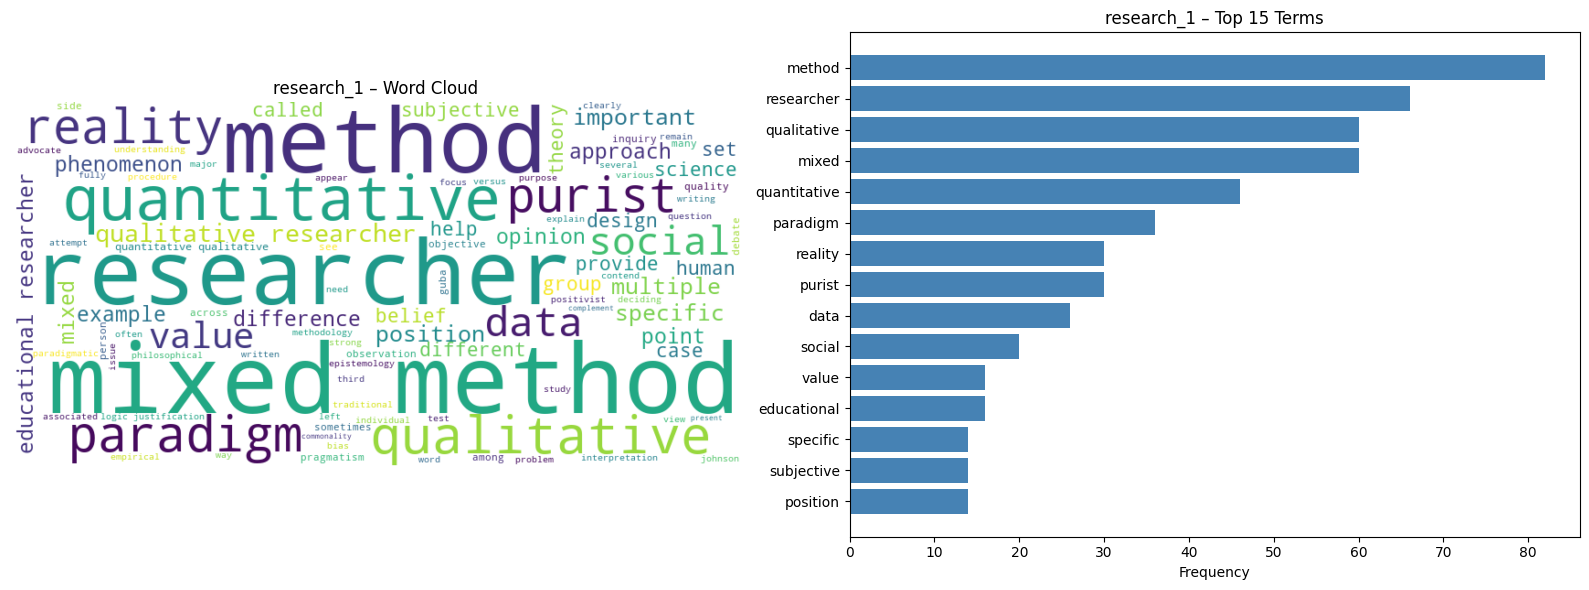


3.4  AGGREGATE SUMMARY OF REMAINING ARTICLES (LDA) + VISUALISATION
Topic 1: alpha, triangulation, instrument, cronbach, reliability, science, method, scale, item, student
Topic 2: reflexivity, position, effect, self, personal, participant, meaning, reaction, woman, share
Topic 3: creating, thought, enable, know, future, expanded, background, comprehensive, communication, represent
Topic 4: development, developmental, design, instructional, model, product, orientation, specific, learning, problem

Document → dominant topic mapping:
  research_2 → Topic 2 (prob=1.00)
  research_3 → Topic 4 (prob=1.00)
  research_4 → Topic 1 (prob=1.00)
  research_5 → Topic 1 (prob=1.00)


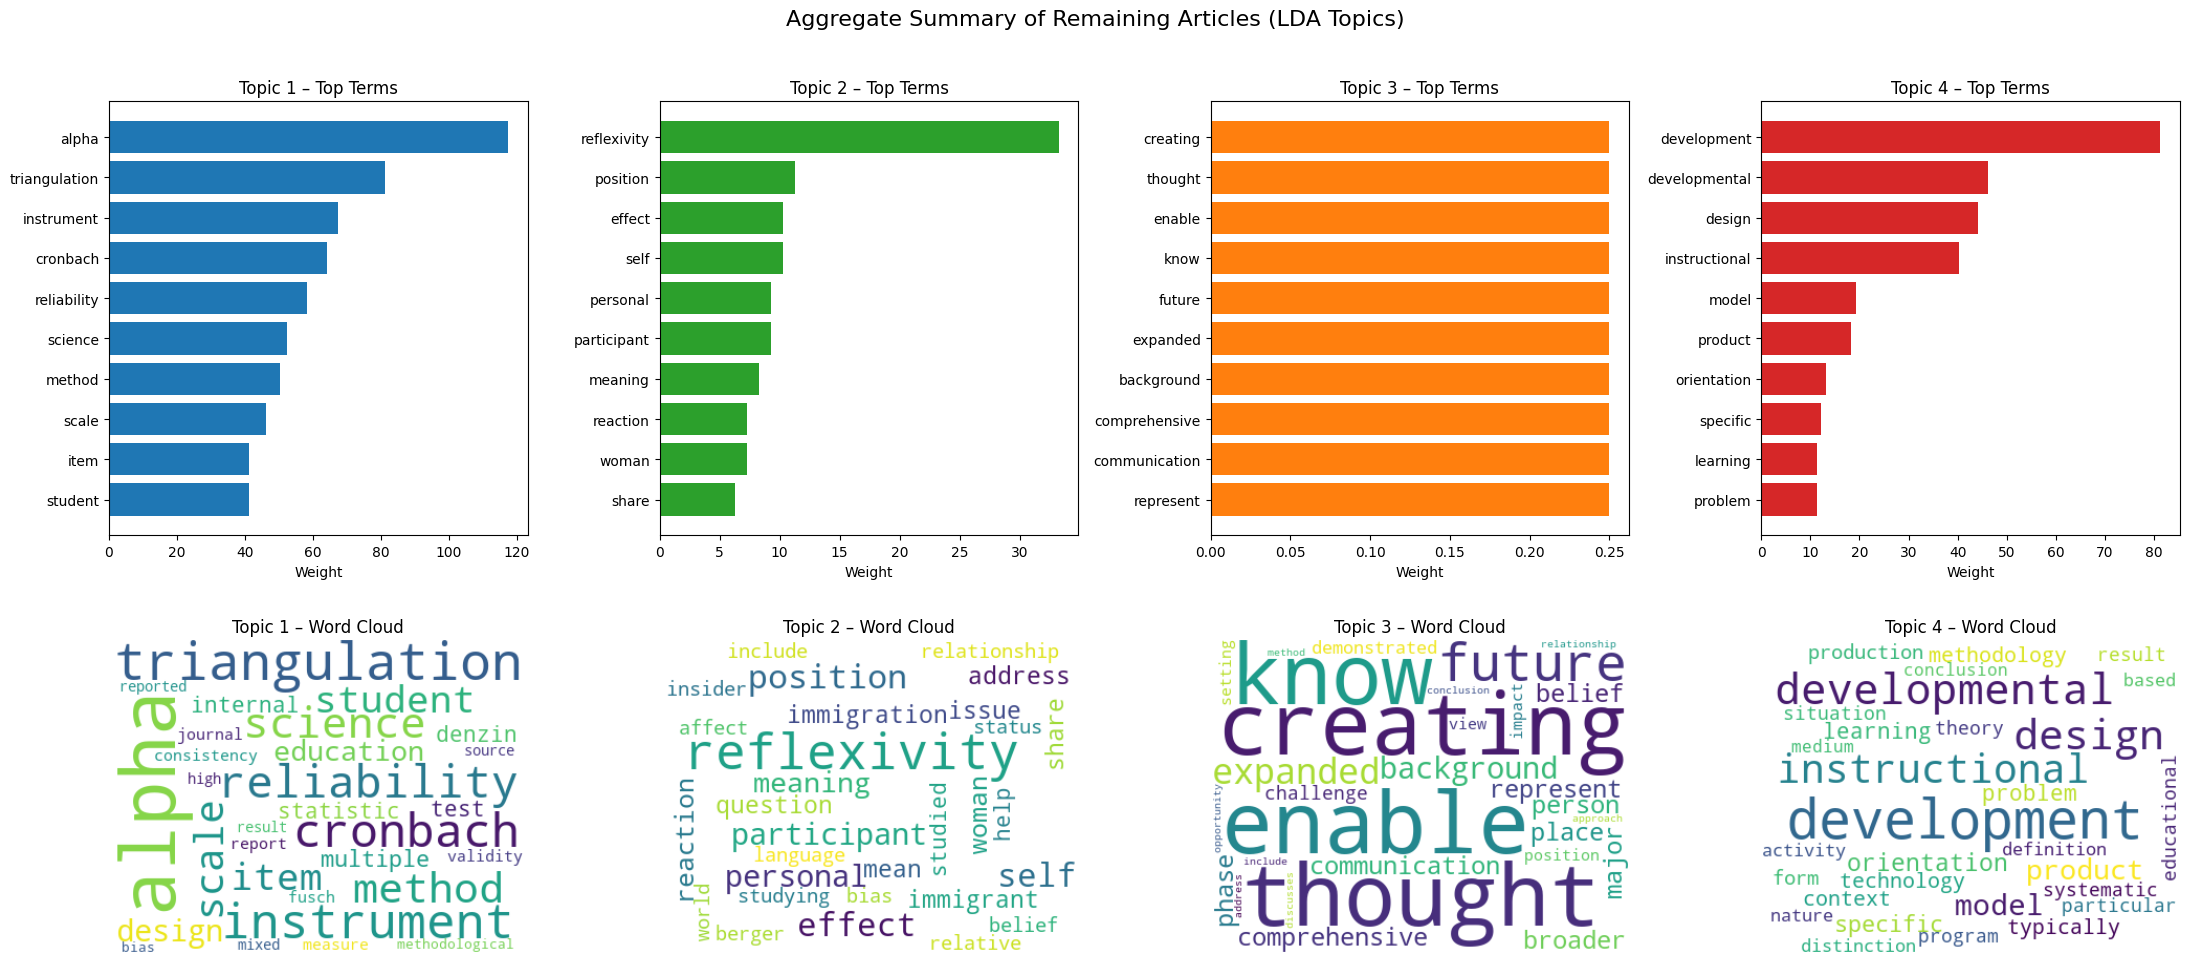

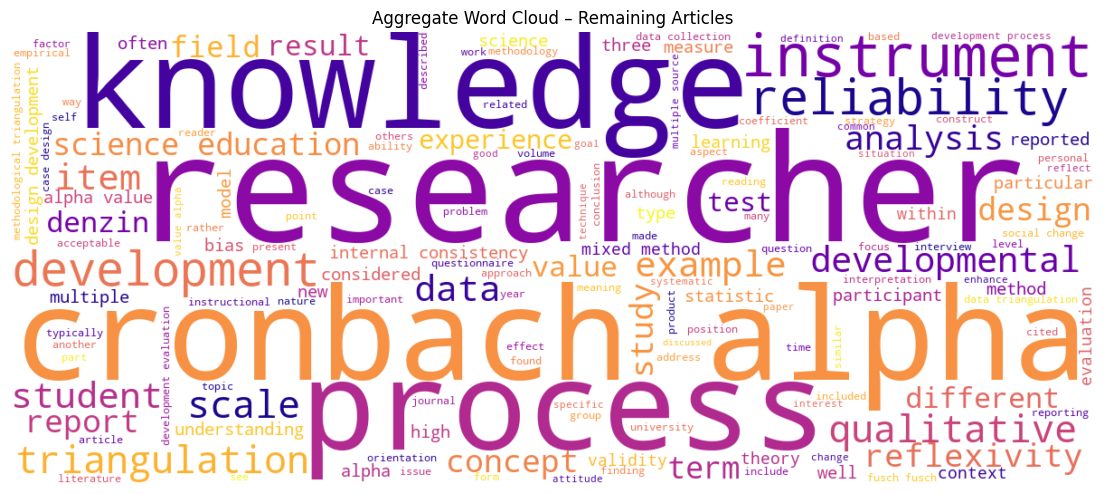

In [1]:
"""
==========================================================================
TOPIC ANALYSIS – RESEARCH DOCUMENT MINING  (Tasks 3.1 – 3.4)
Reads directly from research_corpus.zip   →   Single Jupyter Cell
==========================================================================
"""

import os, re, glob, zipfile, shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(pkg, quiet=True)
    except Exception:
        pass

# ==========================================================================
# STEP 0 – EXTRACT research_corpus.zip  (silent)
# ==========================================================================
ZIP_NAME = "research_corpus.zip"

if not os.path.exists(ZIP_NAME):
    matches = glob.glob("**/" + ZIP_NAME, recursive=True)
    if matches:
        ZIP_NAME = matches[0]
    else:
        raise FileNotFoundError(f"{ZIP_NAME} not found.")

extract_dir = os.path.join(os.getcwd(), "_research_corpus_extracted")
if os.path.isdir(extract_dir):
    shutil.rmtree(extract_dir)
os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, "r") as zf:
    zf.extractall(extract_dir)

txt_files = sorted(glob.glob(os.path.join(extract_dir, "**", "*.txt"),
                              recursive=True))

if not txt_files:
    raise FileNotFoundError("No .txt files found inside research_corpus.zip.")

# ==========================================================================
# 3.1  LOAD RESEARCH ARTICLES INTO A DATAFRAME
# ==========================================================================
print("=" * 72)
print("3.1  LOADING RESEARCH ARTICLES INTO A DATAFRAME")
print("=" * 72)

records = []
for path in txt_files:
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        content = f.read()
    records.append({
        "article_id": os.path.splitext(os.path.basename(path))[0],
        "filename": os.path.basename(path),
        "content": content,
        "char_count": len(content),
        "word_count": len(content.split()),
    })

df = pd.DataFrame(records)
try:
    display(df[["article_id", "filename", "word_count", "char_count"]])
except NameError:
    print(df[["article_id", "filename", "word_count", "char_count"]]
          .to_string(index=False))

# ==========================================================================
# 3.2  DENOISE / PREPROCESS ARTICLE CONTENT
# ==========================================================================
print("\n" + "=" * 72)
print("3.2  DENOISING / PREPROCESSING ARTICLES")
print("=" * 72)

lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))
extra_stops = {"et", "al", "e", "g", "ie", "eg", "cf", "p", "pp", "vol", "no",
               "also", "may", "one", "two", "use", "used", "using", "study",
               "research", "article", "paper", "author", "authors"}
stop_words |= extra_stops


def denoise_text(text: str) -> str:
    text = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", text)
    text = re.sub(r"\([A-Z][A-Za-z\s&.,]+?,?\s*\d{4}[a-z]?\)", " ", text)
    text = re.sub(r"\[\d+(?:[,\-–]\s*\d+)*\]", " ", text)
    text = re.sub(r"\b(Figure|Fig\.?|Table|Chapter|Section|Eq\.?)\s*\d+[\.\d]*",
                  " ", text, flags=re.I)
    text = re.sub(r"\b\d+\b", " ", text)
    text = re.sub(r"[^A-Za-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]
    return " ".join(tokens)


df["clean_content"] = df["content"].apply(denoise_text)
df["clean_word_count"] = df["clean_content"].apply(lambda x: len(x.split()))

try:
    display(df[["article_id", "word_count", "clean_word_count"]])
except NameError:
    print(df[["article_id", "word_count", "clean_word_count"]]
          .to_string(index=False))

print("\nSample cleaned text (first article, first 300 chars):")
print(df.loc[0, "clean_content"][:300], "...")

# ==========================================================================
# 3.3  EXTRACTIVE SUMMARY OF THE FIRST ARTICLE + VISUALISATION
# ==========================================================================
print("\n" + "=" * 72)
print("3.3  EXTRACTIVE SUMMARY OF THE FIRST ARTICLE + VISUALISATION")
print("=" * 72)

first = df.iloc[0]
sentences = sent_tokenize(first["content"])
sentences = [s.strip() for s in sentences if len(s.split()) > 5]

tfidf = TfidfVectorizer(stop_words="english").fit_transform(sentences)
sent_scores = np.asarray(tfidf.sum(axis=1)).ravel()
top_idx = sent_scores.argsort()[::-1][:5]
summary_sentences = [sentences[i] for i in sorted(top_idx)]
summary_1 = " ".join(summary_sentences)

print(f"=== EXTRACTIVE SUMMARY OF ARTICLE: {first['article_id']} ===")
for s in summary_sentences:
    print("•", s, "\n")

compression = len(summary_1.split()) / max(len(first["content"].split()), 1)
print(f"Compression ratio: {compression:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

wc = WordCloud(width=800, height=400, background_color="white",
               max_words=100, colormap="viridis")
wc.generate(first["clean_content"])
axes[0].imshow(wc, interpolation="bilinear")
axes[0].axis("off")
axes[0].set_title(f"{first['article_id']} – Word Cloud")

vec = CountVectorizer(stop_words="english", max_features=15)
counts = vec.fit_transform([first["clean_content"]])
terms_a1 = vec.get_feature_names_out()
freqs = counts.toarray().ravel()
order = freqs.argsort()
axes[1].barh(terms_a1[order], freqs[order], color="steelblue")
axes[1].set_title(f"{first['article_id']} – Top 15 Terms")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.savefig("task_3_3_article1_visualisation.png", dpi=120)
plt.show()

# ==========================================================================
# 3.4  AGGREGATE SUMMARY OF REMAINING ARTICLES (LDA) + VISUALISATION
# ==========================================================================
print("\n" + "=" * 72)
print("3.4  AGGREGATE SUMMARY OF REMAINING ARTICLES (LDA) + VISUALISATION")
print("=" * 72)

remaining = df.iloc[1:].reset_index(drop=True)

if remaining.empty:
    raise ValueError("Corpus contains only one article — 3.4 needs ≥ 2.")

vectorizer = CountVectorizer(max_df=0.95, min_df=1,
                             stop_words="english", max_features=1000)
dtm = vectorizer.fit_transform(remaining["clean_content"])
terms = vectorizer.get_feature_names_out()

N_TOPICS = min(4, len(remaining))
lda = LatentDirichletAllocation(
    n_components=N_TOPICS, random_state=42,
    learning_method="batch", max_iter=50,
)
lda.fit(dtm)


def get_top_terms(model, feature_names, n=10):
    return [[feature_names[i] for i in topic.argsort()[-n:][::-1]]
            for topic in model.components_]


topics = get_top_terms(lda, terms, n=10)
for i, t in enumerate(topics, 1):
    print(f"Topic {i}: {', '.join(t)}")

doc_topic = lda.transform(dtm)
print("\nDocument → dominant topic mapping:")
for i, row in enumerate(doc_topic):
    print(f"  {remaining.loc[i, 'article_id']} → Topic {row.argmax() + 1} "
          f"(prob={row.max():.2f})")

fig, axes = plt.subplots(2, N_TOPICS, figsize=(5.5 * N_TOPICS, 10))
if N_TOPICS == 1:
    axes = np.array([[axes[0]], [axes[1]]])

colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#9467bd", "#8c564b"]

for k in range(N_TOPICS):
    idx = lda.components_[k].argsort()[-10:][::-1]
    t_terms = [terms[i] for i in idx]
    t_weights = [lda.components_[k][i] for i in idx]

    axes[0, k].barh(t_terms[::-1], t_weights[::-1],
                    color=colors[k % len(colors)])
    axes[0, k].set_title(f"Topic {k + 1} – Top Terms")
    axes[0, k].set_xlabel("Weight")

    idx30 = lda.components_[k].argsort()[-30:][::-1]
    freq = {terms[i]: lda.components_[k][i] for i in idx30}
    wc = WordCloud(width=400, height=300, background_color="white")
    wc.generate_from_frequencies(freq)
    axes[1, k].imshow(wc, interpolation="bilinear")
    axes[1, k].axis("off")
    axes[1, k].set_title(f"Topic {k + 1} – Word Cloud")

plt.suptitle("Aggregate Summary of Remaining Articles (LDA Topics)",
             fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("task_3_4_topic_visualisation.png", dpi=120)
plt.show()

agg_wc = WordCloud(width=1200, height=500, background_color="white",
                   max_words=150, colormap="plasma")
agg_wc.generate(" ".join(remaining["clean_content"]))

plt.figure(figsize=(14, 6))
plt.imshow(agg_wc, interpolation="bilinear")
plt.axis("off")
plt.title("Aggregate Word Cloud – Remaining Articles")
plt.savefig("task_3_4_aggregate_wordcloud.png", dpi=120)
plt.show()

